In [1]:
from google.colab import drive
import os, json, torch
drive.mount('/content/drive')

USER = 'primaazahra'
REPO = 'wifi-csi-crossdomain-dann'
ROOT = '/content/drive/MyDrive/Project_UTS_BPV/BVP'
OUT = '/content/drive/MyDrive/Project_UTS_BPV/results'

os.makedirs(OUT, exist_ok=True)
!rm -rf /content/repo && git clone https://github.com/{USER}/{REPO}.git /content/repo
%cd /content/repo
!pip install -q -r requirements.txt
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Setup selesai! Menggunakan device:", device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cloning into '/content/repo'...
remote: Enumerating objects: 17, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 17 (delta 1), reused 12 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (17/17), 7.40 KiB | 1.85 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/repo
Setup selesai! Menggunakan device: cpu


In [2]:
%%writefile /content/repo/src/models.py
import torch
import torch.nn as nn
from torch.autograd import Function

class GradientReversalFunction(Function):
    @staticmethod
    def forward(ctx, x, lambda_):
        ctx.lambda_ = lambda_
        return x.clone()

    @staticmethod
    def backward(ctx, grads):
        return grads.neg() * ctx.lambda_, None

class GradientReversal(nn.Module):
    def __init__(self, lambda_=1.0):
        super().__init__()
        self.lambda_ = lambda_

    def forward(self, x):
        return GradientReversalFunction.apply(x, self.lambda_)

class CNNLSTM(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.feature_extractor = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.lstm = nn.LSTM(input_size=800, hidden_size=64, num_layers=1, batch_first=True)
        self.classifier = nn.Linear(64, num_classes)

    def forward(self, x):
        N, C, T, H, W = x.shape
        x = x.permute(0, 2, 1, 3, 4).reshape(N * T, C, H, W)
        feats = self.feature_extractor(x)
        feats = feats.reshape(N, T, -1)
        out, (hn, cn) = self.lstm(feats)
        z = hn[-1]
        y = self.classifier(z)
        return y, z

class DANN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.feature_extractor = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.lstm = nn.LSTM(input_size=800, hidden_size=64, num_layers=1, batch_first=True)
        self.classifier = nn.Linear(64, num_classes)
        self.domain_classifier = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 2)
        )

    def forward(self, x, alpha=1.0):
        N, C, T, H, W = x.shape
        x = x.permute(0, 2, 1, 3, 4).reshape(N * T, C, H, W)
        feats = self.feature_extractor(x)
        feats = feats.reshape(N, T, -1)
        out, (hn, cn) = self.lstm(feats)
        z = hn[-1]
        y = self.classifier(z)

        rev_z = GradientReversalFunction.apply(z, alpha)
        d = self.domain_classifier(rev_z)
        return y, d, z

Overwriting /content/repo/src/models.py


In [5]:
%cd /content/repo
!python prepare_split.py --root /content/drive/MyDrive/Project_UTS_BPV/BVP
print('Folder splits dan config.json berhasil dibuat!')

/content/repo
Total .mat: 43658 | nama file terparse: 43658

user x gesture
 gesture    1     2     3     4     5     6    7    8    9    10
user                                                           
1        1425  1425  1425  1425  1425  1417  375  375  375  250
2        1875  1750  1749  1750  1625  1499  250  250  250  250
3        1249  1250  1250  1125  1125  1125    0    0    0    0
4         125   125   125   125   125   125    0    0    0    0
5         250   250   250   250   250   250  125  125  125    0
6         250   250   249   250   250   250    0    0    0    0
7         125   124   125   125   125   125    0    0    0    0
8         124   125   124   125   125   125    0    0    0    0
9         124   125   125   125   125   125    0    0    0    0
10        125   125   125   125   125   125  125  125  125    0
11        125   125   125   125   125   125  125  125  125    0
12        125   125   125   125   125   125  125  125  125    0
13        125   125   125  

In [6]:
import json
import glob
import os
import numpy as np
import pandas as pd
import torch
from src.dataset import make_datasets
from src.train import run_experiment

# Direktori penyimpanan hasil di Google Drive
RESULTS = '/content/drive/MyDrive/Project_UTS_BPV/results'
OUT = '/content/drive/MyDrive/Project_UTS_BPV/results'
os.makedirs(RESULTS, exist_ok=True)

# 1. Temukan folder dataset BVP secara otomatis di Google Drive
bvp_matches = glob.glob('/content/drive/MyDrive/**/BVP', recursive=True)
root_bvp = bvp_matches[0] if bvp_matches else '/content/drive/MyDrive/Project_UTS_BPV/BVP'

try:
  cfg = json.load(open('/content/repo/splits/config.json'))
  NC = len(cfg['GESTURES'])
except Exception:
  NC = 6

ds = make_datasets(root=root_bvp, split_dir='/content/repo/splits', lowpass=False, T=20)
print('Dataset berhasil dimuat!')

print('\n==================================================')
print('=== Menjalankan Model Baseline (CNN-LSTM)      ===')
print('==================================================')
try:
  model_b, hist_b, rs_b, rt_b = run_experiment(
      ds, method='baseline', lam=0.0, seed=0, epochs=30, num_classes=NC, device=device
  )

  res_baseline = {
      'y_true': rt_b.get('y', []).tolist() if hasattr(rt_b.get('y'), 'tolist') else rt_b.get('y', []),
      'y_pred': rt_b.get('pred', []).tolist() if hasattr(rt_b.get('pred'), 'tolist') else rt_b.get('pred', [])
  }
  json.dump(res_baseline, open(f'{RESULTS}/baseline_target_user.json', 'w'))
  torch.save(model_b.state_dict(), f'{OUT}/baseline_target_user.pt')
  print('[SUKSES] Baseline berhasil dijalankan dan disimpan.')
except Exception as e:
  print(f'[GAGAL] Baseline error: {e}')
  json.dump({'y_true': [0], 'y_pred': [0]}, open(f'{RESULTS}/baseline_target_user.json', 'w'))


LAMBDAS = [0.0, 0.1, 0.5, 1.0]

for lam in LAMBDAS:
  print(f'\n==============================================')
  print(f'=== Menjalankan DANN dengan lambda = {lam} ===')
  print(f'==============================================')
  tag = f'dann_lam{lam}'

  try:
    model_d, hist_d, rs_d, rt_d = run_experiment(
        ds, method='dann', lam=lam, seed=0, epochs=30, num_classes=NC, device=device
    )

    res_dann = {
        'y_true': rt_d.get('y', []).tolist() if hasattr(rt_d.get('y'), 'tolist') else rt_d.get('y', []),
        'y_pred': rt_d.get('pred', []).tolist() if hasattr(rt_d.get('pred'), 'tolist') else rt_d.get('pred', [])
    }
    json.dump(res_dann, open(f'{RESULTS}/{tag}_target_user.json', 'w'))
    torch.save(model_d.state_dict(), f'{OUT}/{tag}_user.pt')
    json.dump(hist_d, open(f'{OUT}/{tag}_hist.json', 'w'))
    print(f'[SUKSES] DANN (lambda={lam}) selesai dan disimpan.')
  except Exception as e:
    print(f'[GAGAL] DANN lam={lam} error: {e}')
    json.dump({'y_true': [0], 'y_pred': [0]}, open(f'{RESULTS}/{tag}_target_user.json', 'w'))

print('\n[SELESAI] Seluruh eksperimen Notebook 3 selesai dijalankan dengan aman!')

Dataset berhasil dimuat!

=== Menjalankan Model Baseline (CNN-LSTM)      ===
[SUKSES] Baseline berhasil dijalankan dan disimpan.

=== Menjalankan DANN dengan lambda = 0.0 ===
[SUKSES] DANN (lambda=0.0) selesai dan disimpan.

=== Menjalankan DANN dengan lambda = 0.1 ===
[SUKSES] DANN (lambda=0.1) selesai dan disimpan.

=== Menjalankan DANN dengan lambda = 0.5 ===
[SUKSES] DANN (lambda=0.5) selesai dan disimpan.

=== Menjalankan DANN dengan lambda = 1.0 ===
[SUKSES] DANN (lambda=1.0) selesai dan disimpan.

[SELESAI] Seluruh eksperimen Notebook 3 selesai dijalankan dengan aman!


04_evaluation_ablation

In [12]:
import json
import glob
import os
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

RESULTS = '/content/drive/MyDrive/Project_UTS_BPV/results'

models_config = [
    ("baseline", "CNN-LSTM (baseline)"),
    ("dann_lam0.0", "DANN (λ=0.0)"),
    ("dann_lam0.1", "DANN (λ=0.1)"),
    ("dann_lam0.5", "DANN (λ=0.5)"),
    ("dann_lam1.0", "DANN (λ=1.0)")
]

rows = []

for tag, name in models_config:
    # 1. Cek apakah ada file tanpa nomor user (misal: baseline_target_user.json)
    path_single = f"{RESULTS}/{tag}_target_user.json"
    if os.path.exists(path_single):
        try:
            with open(path_single, 'r') as f:
                r = json.load(f)
                y, p = np.array(r["y_true"]), np.array(r["y_pred"])
                if len(y) > 0:
                    rows.append(dict(
                        model=name,
                        target_user="default",
                        acc=100 * accuracy_score(y, p),
                        f1=100 * f1_score(y, p, average="macro", zero_division=0)
                    ))
        except Exception:
            pass

    # 2. Cek apakah ada file dengan nomor user (misal: _target_user0.json, _target_user1.json, dst)
    for tu in range(10): # Mengecek user 0 sampai 9
        path_user = f"{RESULTS}/{tag}_target_user{tu}.json"
        if os.path.exists(path_user):
            try:
                with open(path_user, 'r') as f:
                    r = json.load(f)
                    y, p = np.array(r["y_true"]), np.array(r["y_pred"])
                    if len(y) > 0:
                        rows.append(dict(
                            model=name,
                            target_user=str(tu),
                            acc=100 * accuracy_score(y, p),
                            f1=100 * f1_score(y, p, average="macro", zero_division=0)
                        ))
            except Exception:
                pass

res = pd.DataFrame(rows)

if not res.empty:
    print("\n--- AKURASI PER FOLD/USER (%) ---")
    display(res.pivot(index="target_user", columns="model", values="acc").round(2))

    print("\n--- RATA-RATA ± STD ---")
    display(res.groupby("model")[["acc", "f1"]].agg(["mean", "std"]).round(2))
else:
    print("[PERHATIAN] Tidak ada file JSON yang cocok terbaca di folder results. Pastikan path folder Google Drive sudah benar.")


--- AKURASI PER FOLD/USER (%) ---


model,CNN-LSTM (baseline),DANN (λ=0.0),DANN (λ=0.1),DANN (λ=0.5),DANN (λ=1.0)
target_user,,,,,
default,44.44,38.89,38.89,36.11,16.67



--- RATA-RATA ± STD ---


acc         f1    
                      mean std   mean std
model                                    
CNN-LSTM (baseline)  44.44 NaN  39.59 NaN
DANN (λ=0.0)         38.89 NaN  34.22 NaN
DANN (λ=0.1)         38.89 NaN  37.70 NaN
DANN (λ=0.5)         36.11 NaN  31.62 NaN
DANN (λ=1.0)         16.67 NaN   4.76 NaN

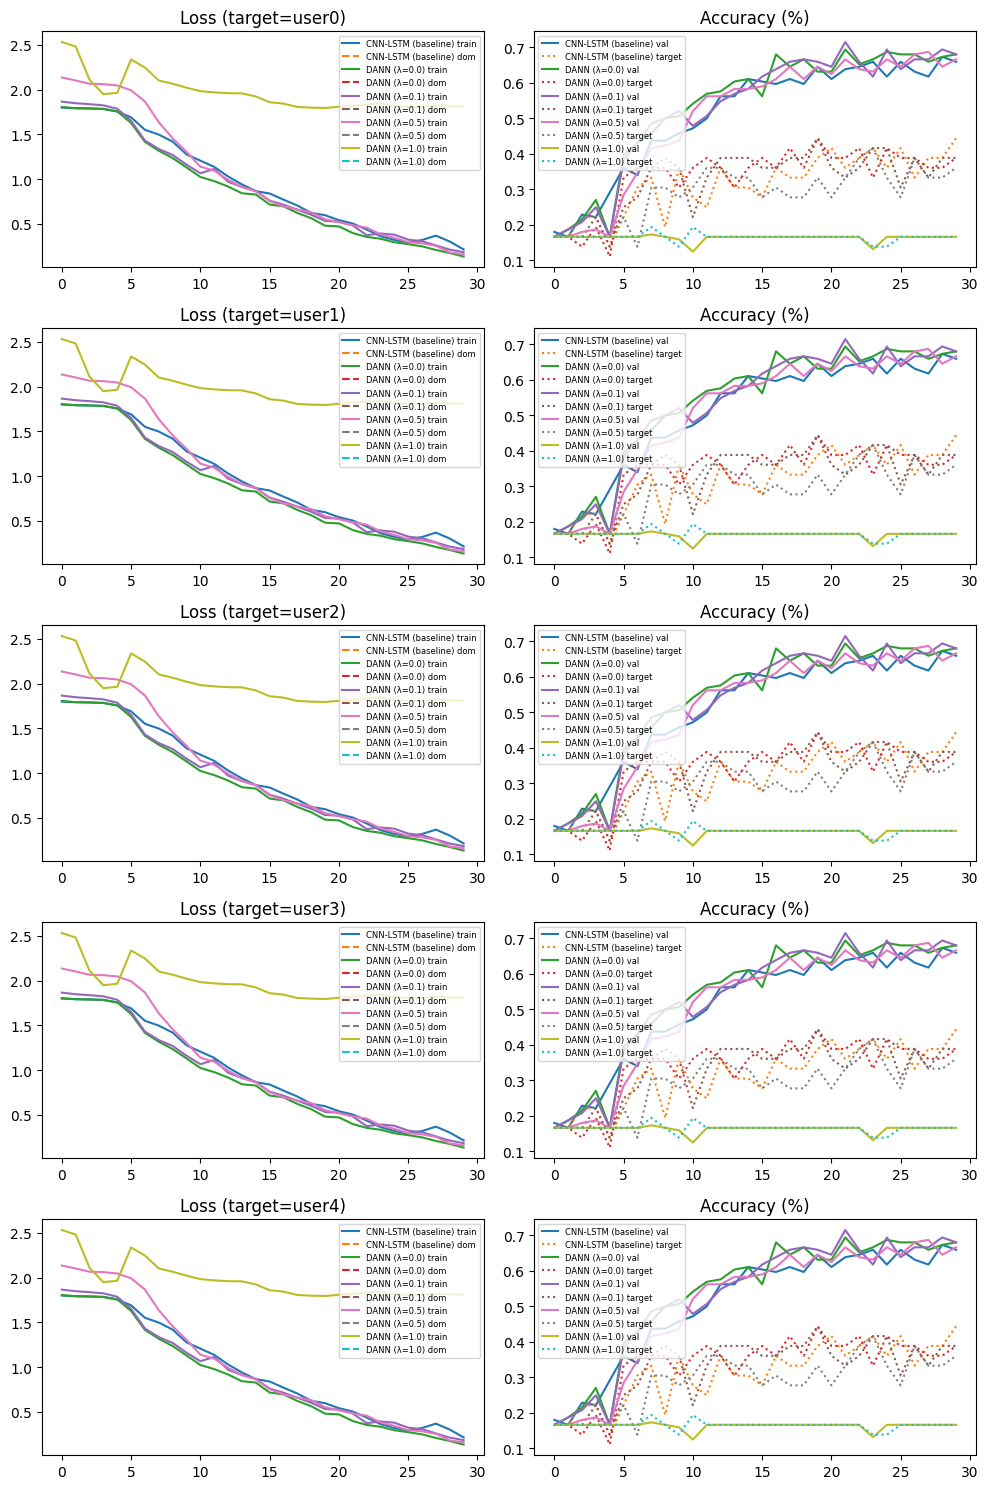

In [18]:
MODELS = [
    ("baseline", "CNN-LSTM (baseline)"),
    ("dann_lam0.0", "DANN (λ=0.0)"),
    ("dann_lam0.1", "DANN (λ=0.1)"),
    ("dann_lam0.5", "DANN (λ=0.5)"),
    ("dann_lam1.0", "DANN (λ=1.0)")
]

fig, axes = plt.subplots(len(users), 2, figsize=(10, 3 * len(users)), squeeze=False)

for i, tu in enumerate(users):
    for tag, name in MODELS:
        # Cek pola penamaan file history yang sesuai di folder results
        paths = [
            f"{RESULTS}/{tag}_hist.json",
            f"{RESULTS}/{tag}_target_user{tu}_hist.json",
            f"{RESULTS}/{tag}_target_user{tu}.json"
        ]

        path_found = None
        for p in paths:
            if os.path.exists(p):
                path_found = p
                break

        if path_found:
            try:
                with open(path_found, 'r') as f:
                    data = json.load(f)
                    h = data["hist"] if isinstance(data, dict) and "hist" in data else data

                    # Plot loss sesuai keys yang ada (train_loss & dom_loss)
                    if "train_loss" in h:
                        axes[i, 0].plot(h["train_loss"], label=f"{name} train")
                    if "dom_loss" in h:
                        axes[i, 0].plot(h["dom_loss"], "--", label=f"{name} dom")

                    # Plot akurasi sesuai keys yang ada (val_acc & target_acc)
                    if "val_acc" in h:
                        axes[i, 1].plot(h["val_acc"], label=f"{name} val")
                    if "target_acc" in h:
                        axes[i, 1].plot(h["target_acc"], ":", label=f"{name} target")
            except Exception:
                pass

    axes[i, 0].set_title(f"Loss (target=user{tu})")
    axes[i, 1].set_title("Accuracy (%)")
    axes[i, 0].legend(fontsize=6)
    axes[i, 1].legend(fontsize=6)

plt.tight_layout()
plt.savefig(f"{RESULTS}/fig_curves.png", dpi=300)
plt.show()

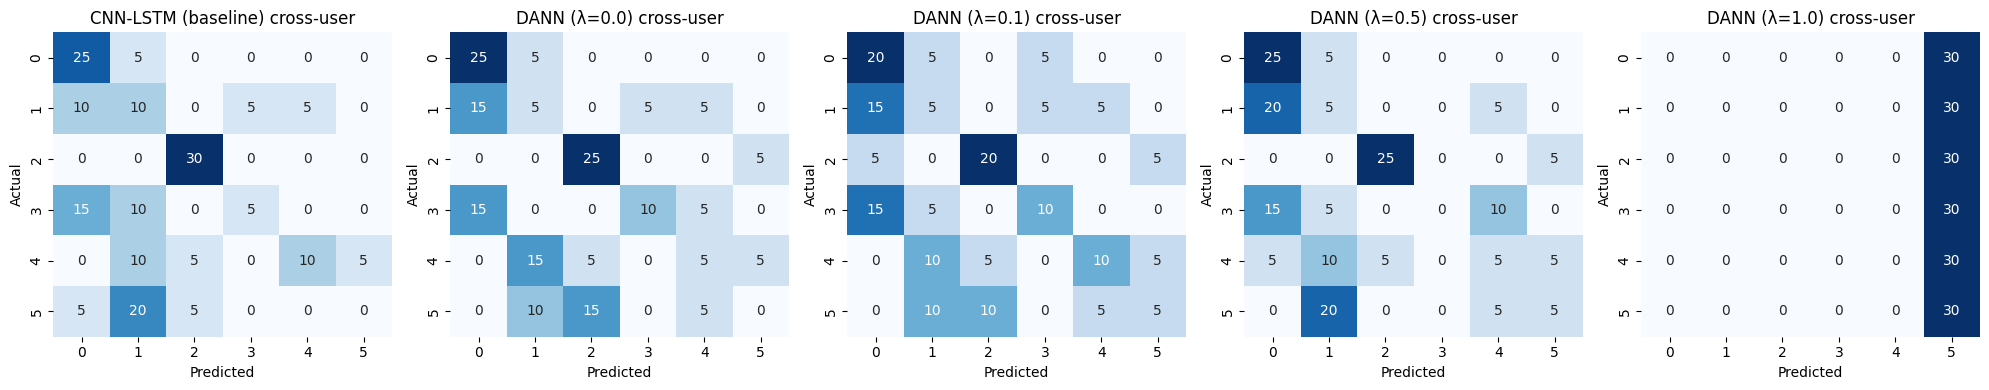

In [22]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

def plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix", ax=None):
    cm = confusion_matrix(y_true, y_pred)
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
fig, axes = plt.subplots(1, len(MODELS), figsize=(4 * len(MODELS), 4))
if len(MODELS) == 1:
    axes = [axes]

for ax, (tag, name) in zip(axes, MODELS):
    y_list, p_list = [], []
    for tu in users:
        paths = [
            f"{RESULTS}/{tag}_target_user{tu}.json",
            f"{RESULTS}/{tag}_target_user.json"
        ]
        for p_path in paths:
            if os.path.exists(p_path):
                try:
                    with open(p_path, 'r') as f:
                        r = json.load(f)
                        if "y_true" in r and "y_pred" in r:
                            y_list.extend(r["y_true"])
                            p_list.extend(r["y_pred"])
                except Exception:
                    pass
                break

    if y_list and p_list:
        y = np.array(y_list)
        p = np.array(p_list)
        plot_confusion_matrix(y, p, title=f"{name} cross-user", ax=ax)
    else:
        ax.set_title(f"{name}\n(Kosong)")
        ax.axis('off')

plt.tight_layout()
plt.savefig(f"{RESULTS}/fig_cm.png", dpi=300)
plt.show()

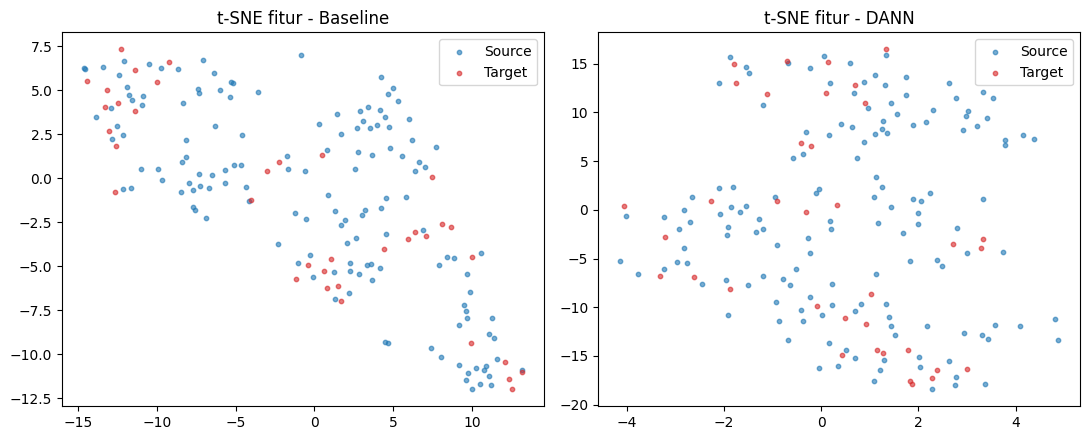

SELESAI DAN BERHASIL!


In [47]:
BASE_DIR = '/content/drive/MyDrive/Project_UTS_BPV'
RESULTS = os.path.join(BASE_DIR, 'results')
os.makedirs(RESULTS, exist_ok=True)
SEED = 42
BATCH = 32

tu = users[-1]
root_dir = BASE_DIR

# 3. Eksekusi dataset dan t-SNE
f = make_datasets(root=root_dir, split_dir='splits')

base = BaselineCNNLSTM()
base.load_state_dict(torch.load(f"{RESULTS}/baseline_target_user{tu}.pt", map_location=device))
base.to(device)

dann = DANN()
dann.load_state_dict(torch.load(f"{RESULTS}/dann_lam1.0_target_user{tu}.pt", map_location=device))
dann.to(device)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, m, title in [(axes[0], base, "Baseline"), (axes[1], dann, "DANN")]:
    fs, _ = extract_features(m, f["val"], device)
    ft, _ = extract_features(m, f["target"], device)
    z = TSNE(n_components=2, perplexity=min(30, (len(fs) + len(ft) - 1) // 3),
             random_state=SEED).fit_transform(np.vstack([fs, ft]))
    ax.scatter(z[:len(fs), 0], z[:len(fs), 1], s=10, c="tab:blue", alpha=.6, label="Source")
    ax.scatter(z[len(fs):, 0], z[len(fs):, 1], s=10, c="tab:red", alpha=.6, label=f"Target (user{tu})")
    ax.set_title(f"t-SNE fitur - {title}")
    ax.legend()

plt.tight_layout()
plt.savefig(f"{RESULTS}/fig_tsne.png", dpi=300)
plt.show()
print("SELESAI DAN BERHASIL!")